# AR, MA, ARMA, and the Box-Jenkins Methodology

This notebook is a statistical companion to `08_time_series`. It goes deeper into the classical
**Box-Jenkins** approach: identify a model from the data, estimate its parameters, check the
residuals, forecast, and iterate.

The focus is on the family of models behind ARIMA:

- **AR(p):** autoregressive models;
- **MA(q):** moving-average models;
- **ARMA(p, q):** a combination of AR and MA;
- **ARIMA(p, d, q):** ARMA after differencing `d` times.

## Learning objectives

By the end of this notebook you can:

- write the equations for AR, MA, ARMA, and ARIMA models;
- interpret ACF and PACF patterns used for model identification;
- explain the four steps of the Box-Jenkins methodology;
- fit and compare candidate ARIMA models with AIC and BIC;
- check residuals with ACF plots and the Ljung-Box test;
- produce forecast intervals and evaluate forecasts against a naive baseline;
- explain the main cautions: stationarity, over-differencing, seasonality, structural breaks,
  model-selection uncertainty, and causality.

## 1. What is the Box-Jenkins methodology?

The Box-Jenkins methodology is an iterative workflow for building ARIMA models. It is not a single
test or a single model. The four steps are:

1. **Identification:** transform the series to stationarity if needed, then use plots, ACF, PACF,
   and unit-root tests to propose candidate orders `(p, d, q)`.
2. **Estimation:** fit the candidate models and estimate their parameters, usually by maximum
   likelihood.
3. **Diagnostic checking:** test whether the residuals look like white noise. If they do not,
   return to identification.
4. **Forecasting:** use the validated model to forecast, with prediction intervals, and evaluate
   forecast accuracy out of sample.

The loop matters. A model with a low AIC is not automatically a good model if its residuals still
contain autocorrelation or if it fails out of sample.

### Stationarity and the backshift operator

A time series is **strictly stationary** if its joint distribution does not change when time is
shifted. In practice we usually require **weak stationarity**: constant mean, constant variance, and
autocovariance that depends only on the lag.

The backshift operator `B` moves a series back one period:

`B y_t = y_{t-1}`, `B^k y_t = y_{t-k}`.

An ARMA model can be written compactly as

`phi(B) y_t = theta(B) epsilon_t`,

where `phi(B) = 1 - phi_1 B - ... - phi_p B^p` and
`theta(B) = 1 + theta_1 B + ... + theta_q B^q`.

An ARIMA(p, d, q) model applies `d` differences before the ARMA structure:

`phi(B) (1 - B)^d y_t = theta(B) epsilon_t`.

## 2. AR, MA, ARMA, and ARIMA models

### AR(p): autoregressive

`y_t = c + phi_1 y_{t-1} + ... + phi_p y_{t-p} + epsilon_t`

The current value depends on its own past values. An AR(1) model is stationary when `|phi_1| < 1`.
Its ACF decays gradually (tails off), while its PACF cuts off after lag `p`.

### MA(q): moving average

`y_t = mu + epsilon_t + theta_1 epsilon_{t-1} + ... + theta_q epsilon_{t-q}`

The current value depends on current and past forecast errors (shocks). An MA(q) model is always
stationary. It is **invertible** when its MA roots lie outside the unit circle, which lets us write
it as an infinite AR process. Its ACF cuts off after lag `q`, while its PACF tails off.

### ARMA(p, q)

`y_t = c + sum_i phi_i y_{t-i} + epsilon_t + sum_j theta_j epsilon_{t-j}`

ARMA combines both mechanisms. Its ACF and PACF usually both tail off, so identification is less
mechanical than for pure AR or pure MA models.

### ARIMA(p, d, q)

ARIMA applies ARMA to the `d`-th difference of the series:

`w_t = (1 - B)^d y_t`, then fit ARMA(p, q) to `w_t`.

Use `d = 1` for a series with a stable linear trend or a random walk. Use `d = 0` when the series is
already stationary. Seasonal data often need a seasonal difference plus a seasonal ARMA structure
(SARIMA).

## 3. ACF and PACF identification guide

| Model | ACF | PACF |
| --- | --- | --- |
| AR(p) | tails off | cuts off after lag p |
| MA(q) | cuts off after lag q | tails off |
| ARMA(p, q) | tails off | tails off |

These are patterns from the **theoretical** autocorrelation functions. Sample ACF and PACF plots
are noisy, especially in short series, so use them as evidence rather than as a rigid rule. Combine
them with unit-root tests, parameter significance, information criteria, and residual diagnostics.

In [1]:
import os
import warnings

os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")
warnings.filterwarnings("ignore", message="A NumPy version")
warnings.filterwarnings("ignore", message="Could not find the number of physical cores")
warnings.filterwarnings("ignore", category=UserWarning, module="joblib")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tools.sm_exceptions import ConvergenceWarning, InterpolationWarning
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller, kpss

warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=InterpolationWarning)
warnings.filterwarnings("ignore", message="Non-invertible starting MA parameters found")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 4)
np.set_printoptions(precision=3, suppress=True)

## 4. Simulating AR, MA, and ARMA processes

Simulation makes the ACF/PACF signatures visible. The three panels below use the same shock scale
but different dependence structures.

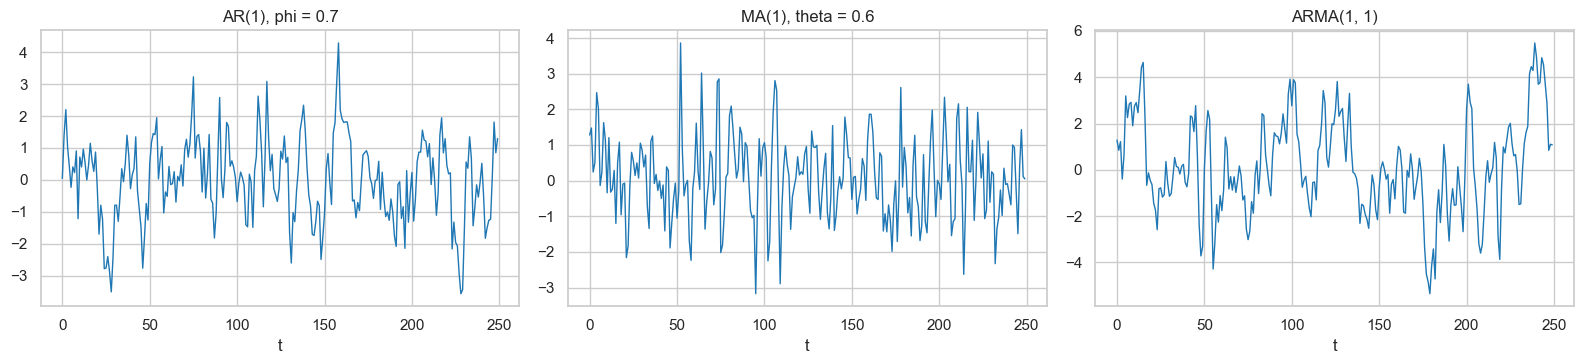

In [2]:
def simulate_ar1(phi, n, rng, sigma=1.0):
    eps = rng.normal(0, sigma, n)
    y = np.zeros(n)
    y[0] = eps[0] / np.sqrt(1 - phi ** 2)
    for t in range(1, n):
        y[t] = phi * y[t - 1] + eps[t]
    return y


def simulate_ma1(theta, n, rng, sigma=1.0):
    eps = rng.normal(0, sigma, n + 1)
    return eps[1:] + theta * eps[:-1]


def simulate_arma11(phi, theta, n, rng, sigma=1.0, burn=100):
    eps = rng.normal(0, sigma, n + burn)
    y = np.zeros(n + burn)
    for t in range(1, n + burn):
        y[t] = phi * y[t - 1] + eps[t] + theta * eps[t - 1]
    return y[burn:]


rng = np.random.default_rng(11)
ar1 = simulate_ar1(phi=0.7, n=250, rng=rng)
ma1 = simulate_ma1(theta=0.6, n=250, rng=rng)
arma11 = simulate_arma11(phi=0.7, theta=0.5, n=250, rng=rng)

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, series, title in zip(
    axes,
    [ar1, ma1, arma11],
    ["AR(1), phi = 0.7", "MA(1), theta = 0.6", "ARMA(1, 1)"],
):
    ax.plot(series, color="tab:blue", linewidth=1)
    ax.set_title(title)
    ax.set_xlabel("t")
plt.tight_layout()
plt.show()

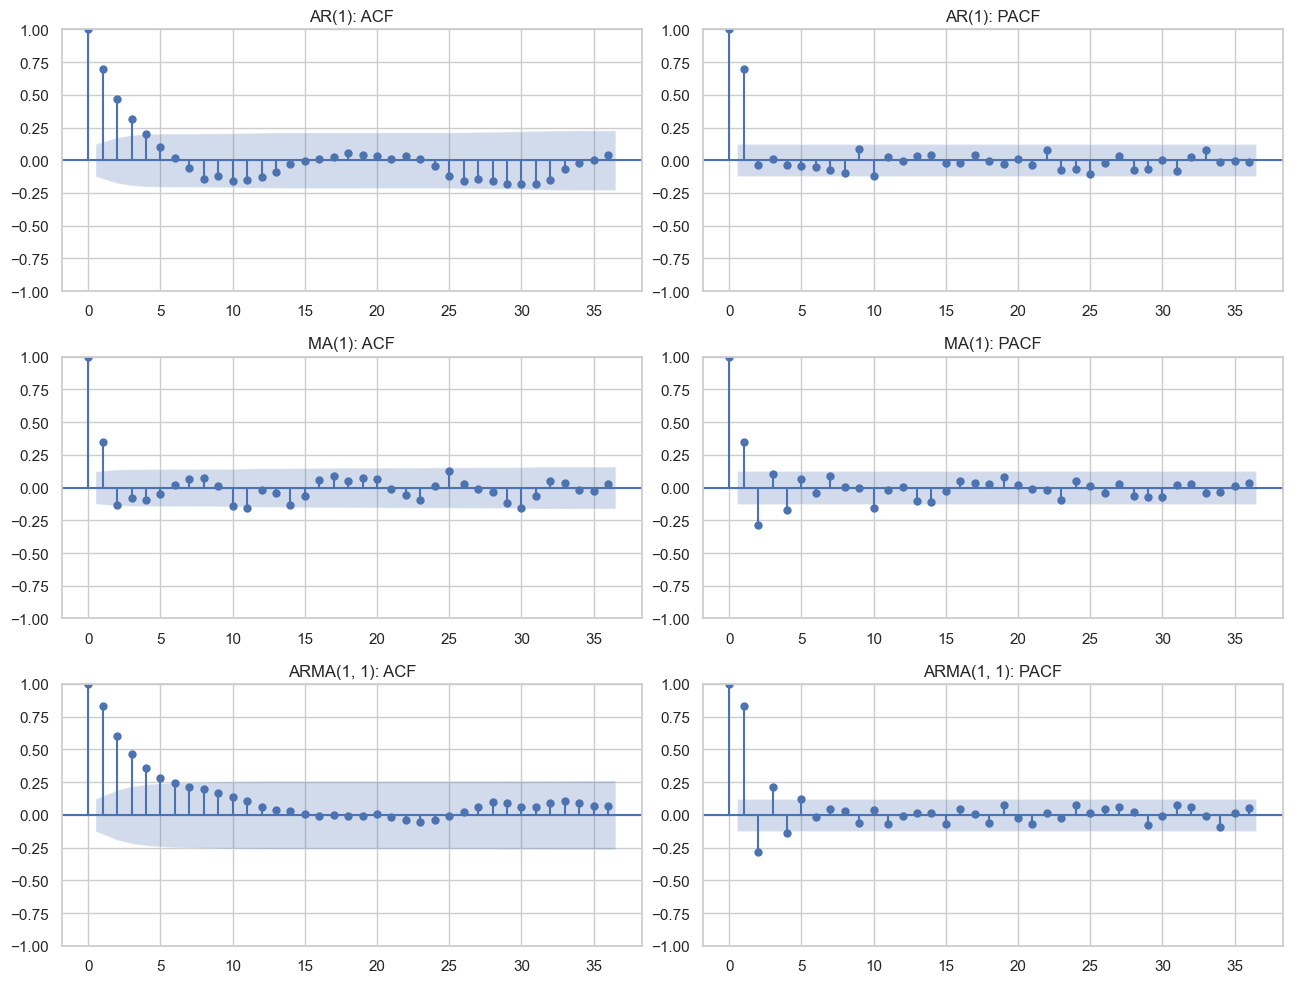

In [3]:
fig, axes = plt.subplots(3, 2, figsize=(13, 10))
series_info = [("AR(1)", ar1), ("MA(1)", ma1), ("ARMA(1, 1)", arma11)]

for row, (name, series) in enumerate(series_info):
    plot_acf(series, lags=36, ax=axes[row, 0], title=f"{name}: ACF")
    plot_pacf(series, lags=36, ax=axes[row, 1], title=f"{name}: PACF", method="ywm")

plt.tight_layout()
plt.show()

**Reading the plots.** The AR(1) ACF decays slowly while its PACF is large mainly at lag 1. The
MA(1) ACF is large at lag 1 and then cuts off, while its PACF decays. The ARMA(1, 1) has both ACF
and PACF tailing off. Real data will be noisier than these simulated examples.

## 5. Random walks, unit roots, and differencing

A random walk is

`y_t = y_{t-1} + epsilon_t`.

It is nonstationary: its variance grows with time, and shocks have permanent effects. Its ACF
usually decays very slowly. First differences recover white noise.

Two tests are useful together:

- **ADF test:** null hypothesis is a unit root (nonstationary). A small p-value favours
  stationarity.
- **KPSS test:** null hypothesis is stationarity. A small p-value favours a unit root.

Using both helps avoid drawing a conclusion from a single test.

Levels: ADF p-value = 0.3074, KPSS p-value = 0.0100
First differences: ADF p-value = 0.0000, KPSS p-value = 0.1000


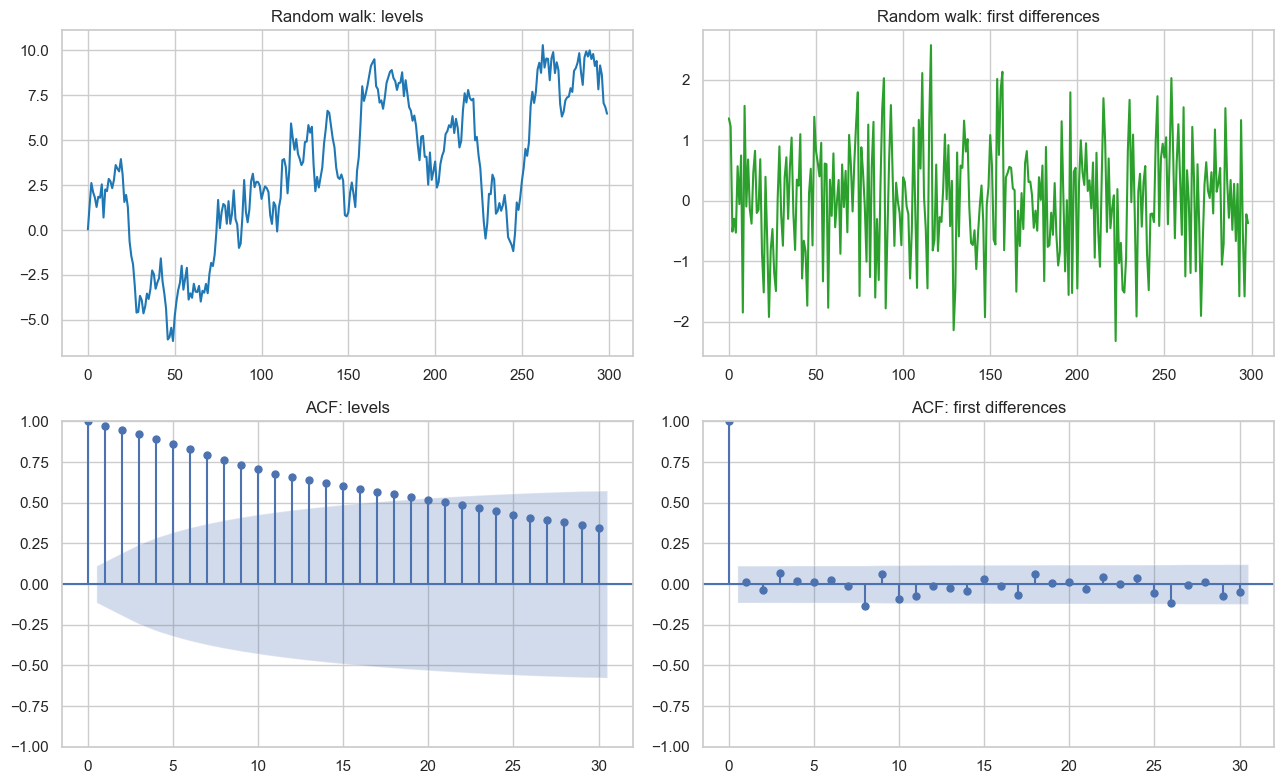

In [4]:
rw_rng = np.random.default_rng(11)
rw = np.cumsum(rw_rng.normal(0, 1, 300))
rw_diff = np.diff(rw)

for name, values in [("Levels", rw), ("First differences", rw_diff)]:
    adf_p = adfuller(values, autolag="AIC")[1]
    kpss_p = kpss(values, regression="c", nlags="auto")[1]
    print(f"{name}: ADF p-value = {adf_p:.4f}, KPSS p-value = {kpss_p:.4f}")

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
axes[0, 0].plot(rw, color="tab:blue")
axes[0, 0].set_title("Random walk: levels")
axes[0, 1].plot(rw_diff, color="tab:green")
axes[0, 1].set_title("Random walk: first differences")
plot_acf(rw, lags=30, ax=axes[1, 0], title="ACF: levels")
plot_acf(rw_diff, lags=30, ax=axes[1, 1], title="ACF: first differences")
plt.tight_layout()
plt.show()

The level series fails to reject a unit root in the ADF test, while the differenced series looks
stationary. The level ACF decays slowly; the differenced ACF is close to zero after lag 0. This is
the standard argument for `d = 1` on a random walk.

Do not difference automatically. Over-differencing can induce a unit root in the MA part, increase
variance, and make the model harder to estimate.

## 6. Box-Jenkins in practice: an ARMA(1, 1) example

We now generate a stationary ARMA(1, 1) series with known parameters, split it into train and test,
and run the Box-Jenkins loop.

The data-generating process is

`y_t = 0.7 y_{t-1} + epsilon_t + 0.5 epsilon_{t-1}`, with `epsilon_t ~ N(0, 1)`.

The training sample is used for identification and estimation. The final 50 observations are held
out for forecast evaluation.

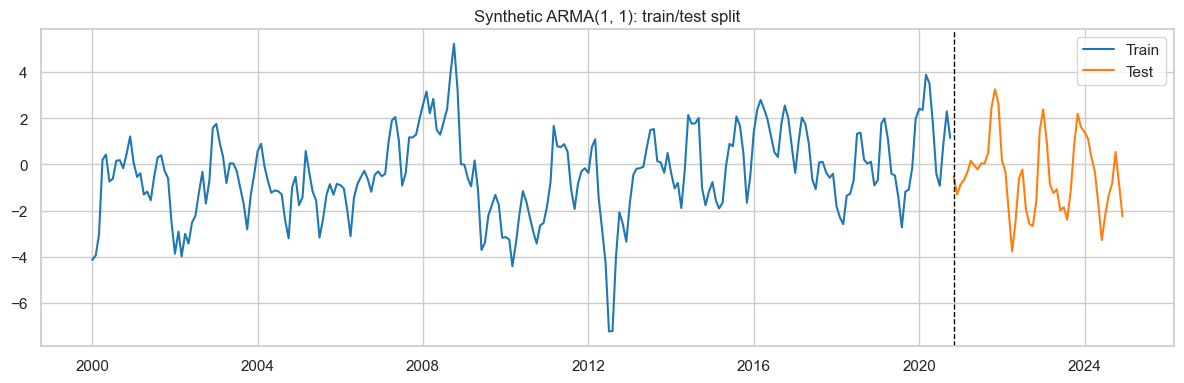

In [5]:
rng = np.random.default_rng(7)
n = 300
y = simulate_arma11(phi=0.7, theta=0.5, n=n, rng=rng)
dates = pd.date_range("2000-01-01", periods=n, freq="MS")
series = pd.Series(y, index=dates, name="ARMA(1, 1)")

train = series.iloc[:250]
test = series.iloc[250:]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(train.index, train, label="Train", color="tab:blue")
ax.plot(test.index, test, label="Test", color="tab:orange")
ax.axvline(test.index[0], color="black", linestyle="--", linewidth=1)
ax.set_title("Synthetic ARMA(1, 1): train/test split")
ax.legend()
plt.tight_layout()
plt.show()

### Step 1: Identification

Check stationarity and inspect the ACF and PACF on the training data. Because the series is
stationary by construction, we expect `d = 0`. The ACF and PACF should both tail off, which suggests
an ARMA model rather than a pure AR or pure MA model.

ADF p-value:  0.0000  (small favours stationarity)
KPSS p-value: 0.0964  (small favours a unit root)


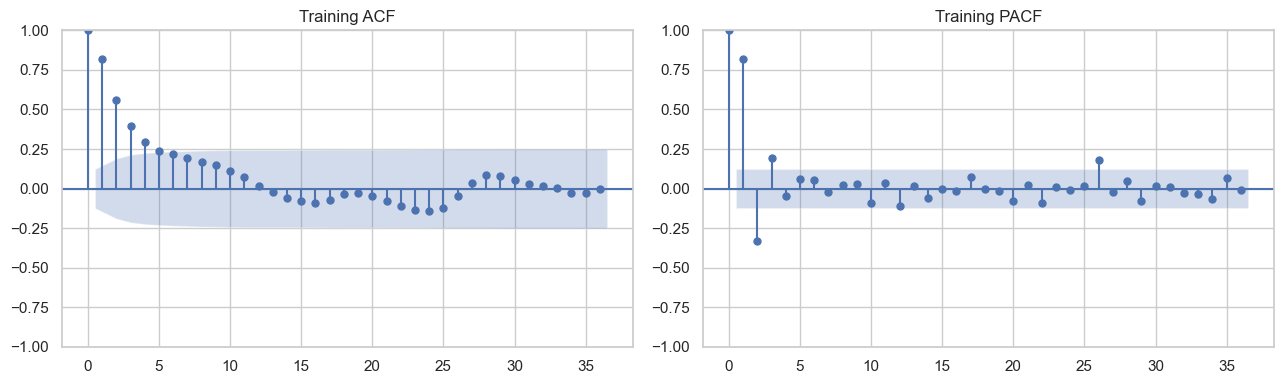

In [6]:
adf_p = adfuller(train, autolag="AIC")[1]
kpss_p = kpss(train, regression="c", nlags="auto")[1]
print(f"ADF p-value:  {adf_p:.4f}  (small favours stationarity)")
print(f"KPSS p-value: {kpss_p:.4f}  (small favours a unit root)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_acf(train, lags=36, ax=axes[0], title="Training ACF")
plot_pacf(train, lags=36, ax=axes[1], title="Training PACF", method="ywm")
plt.tight_layout()
plt.show()

### Step 2: Estimation and model comparison

Fit a small set of candidate ARIMA models with `d = 0`. Compare them with AIC and BIC:

- **AIC** rewards fit and penalises parameters by `2k`; it tends to favour larger models.
- **BIC** penalises by `k log(n)`; it tends to favour smaller models.

Lower is better for both. Information criteria are relative, not absolute, measures.

In [7]:
orders = [
    (1, 0, 0),
    (0, 0, 1),
    (1, 0, 1),
    (2, 0, 0),
    (0, 0, 2),
    (2, 0, 1),
    (1, 0, 2),
]

fits = {}
for order in orders:
    fits[order] = ARIMA(train, order=order).fit()

comparison = pd.DataFrame(
    [
        {
            "order": f"({p}, {d}, {q})",
            "p": p,
            "d": d,
            "q": q,
            "AIC": fit.aic,
            "BIC": fit.bic,
            "log-likelihood": fit.llf,
        }
        for (p, d, q), fit in fits.items()
    ]
).sort_values("AIC").reset_index(drop=True)

best_order = min(fits, key=lambda order: fits[order].aic)
print(f"Selected by AIC: ARIMA{best_order}")
print(comparison.round(2).to_string(index=False))

Selected by AIC: ARIMA(1, 0, 1)
    order  p  d  q    AIC    BIC  log-likelihood
(1, 0, 1)  1  0  1 692.62 706.70         -342.31
(1, 0, 2)  1  0  2 694.53 712.14         -342.27
(2, 0, 1)  2  0  1 694.54 712.15         -342.27
(2, 0, 0)  2  0  0 705.17 719.25         -348.58
(0, 0, 2)  0  0  2 725.58 739.67         -358.79
(1, 0, 0)  1  0  0 733.42 743.98         -363.71
(0, 0, 1)  0  0  1 793.18 803.75         -393.59


With this simulation, the true ARMA(1, 1) model has the lowest AIC and BIC. In real data the choice
is often less clear, so retain a small set of plausible models and compare them out of sample.

### Step 3: Estimation and parameter interpretation

The fitted model is selected by AIC. Inspect the coefficients, standard errors, and p-values. A
coefficient that is not statistically distinguishable from zero may justify a simpler model, but
do not drop terms mechanically: model selection and residual diagnostics should agree.

In [8]:
best_fit = fits[best_order]
print(f"Best model: ARIMA{best_order}")
print(best_fit.summary())

Best model: ARIMA(1, 0, 1)
                               SARIMAX Results                                
Dep. Variable:             ARMA(1, 1)   No. Observations:                  250
Model:                 ARIMA(1, 0, 1)   Log Likelihood                -342.308
Date:                Wed, 18 Nov 2026   AIC                            692.616
Time:                        22:01:54   BIC                            706.702
Sample:                    01-01-2000   HQIC                           698.285
                         - 10-01-2020                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.4628      0.288     -1.608      0.108      -1.027       0.101
ar.L1          0.6913      0.049     14.229      0.000       0.596       0.787
ma.L1          0.5177    

In [9]:
param_table = pd.DataFrame(
    {
        "estimate": best_fit.params,
        "std_error": best_fit.bse,
        "p_value": best_fit.pvalues,
    }
)
print(param_table.round(4).to_string())

ar_roots = best_fit.arroots if len(best_fit.arparams) else np.array([])
ma_roots = best_fit.maroots if len(best_fit.maparams) else np.array([])

print("\nAR roots:", ar_roots if len(ar_roots) else "none")
print("MA roots:", ma_roots if len(ma_roots) else "none")
print("AR root magnitudes:", np.abs(ar_roots) if len(ar_roots) else "none")
print("MA root magnitudes:", np.abs(ma_roots) if len(ma_roots) else "none")
print("\nStationarity requires AR roots outside the unit circle (magnitude > 1).")
print("Invertibility requires MA roots outside the unit circle (magnitude > 1).")

        estimate  std_error  p_value
const    -0.4628     0.2878   0.1078
ar.L1     0.6913     0.0486   0.0000
ma.L1     0.5177     0.0631   0.0000
sigma2    0.8997     0.0851   0.0000

AR roots: [1.447]
MA roots: [-1.932]
AR root magnitudes: [1.447]
MA root magnitudes: [1.932]

Stationarity requires AR roots outside the unit circle (magnitude > 1).
Invertibility requires MA roots outside the unit circle (magnitude > 1).


### Step 4: Diagnostic checking

The model is only credible if its residuals look like white noise. Check:

- the residual time plot for changing variance or remaining structure;
- the residual ACF for significant spikes;
- the histogram and Q-Q plot for severe non-normality;
- the Ljung-Box test, whose null hypothesis is that the first `m` residual autocorrelations are
  zero.

A Ljung-Box p-value above 0.05 is consistent with white-noise residuals. Failure to reject is not
proof that the model is correct, but rejection is a clear warning.

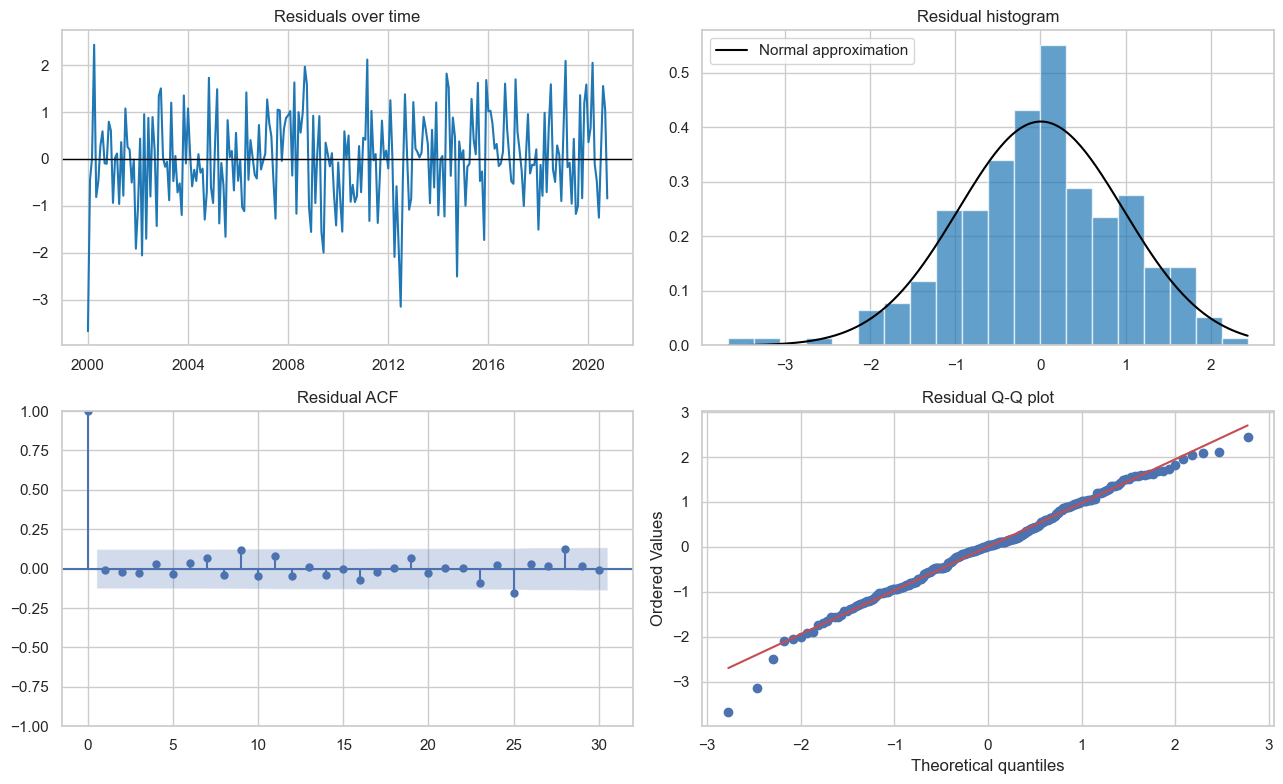

In [10]:
resid = best_fit.resid

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
axes[0, 0].plot(resid, color="tab:blue")
axes[0, 0].axhline(0, color="black", linewidth=1)
axes[0, 0].set_title("Residuals over time")

axes[0, 1].hist(resid, bins=20, density=True, alpha=0.7, color="tab:blue")
x_grid = np.linspace(resid.min(), resid.max(), 200)
axes[0, 1].plot(
    x_grid,
    stats.norm.pdf(x_grid, resid.mean(), resid.std()),
    color="black",
    linewidth=1.5,
    label="Normal approximation",
)
axes[0, 1].set_title("Residual histogram")
axes[0, 1].legend()

plot_acf(resid, lags=30, ax=axes[1, 0], title="Residual ACF")
stats.probplot(resid, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title("Residual Q-Q plot")
plt.tight_layout()
plt.show()

In [11]:
ljung_box = acorr_ljungbox(resid, lags=[5, 10, 20], return_df=True)
print(ljung_box.round(4).to_string())

    lb_stat  lb_pvalue
5    0.8646     0.9727
10   6.9329     0.7318
20  12.5637     0.8953


The Ljung-Box p-values are comfortably above 0.05 here, so there is no strong evidence of remaining
autocorrelation. If a test rejected, we would consider a larger AR or MA order, a seasonal term, or
a structural break rather than forcing the current model to fit.

### Step 5: Forecasting and backtesting

Forecast the held-out period and compare against a naive forecast that repeats the last training
value. The prediction interval reflects parameter uncertainty and future shocks; it should widen as
the horizon grows.

Always evaluate with out-of-sample metrics such as MAE and RMSE, not only with AIC or BIC.

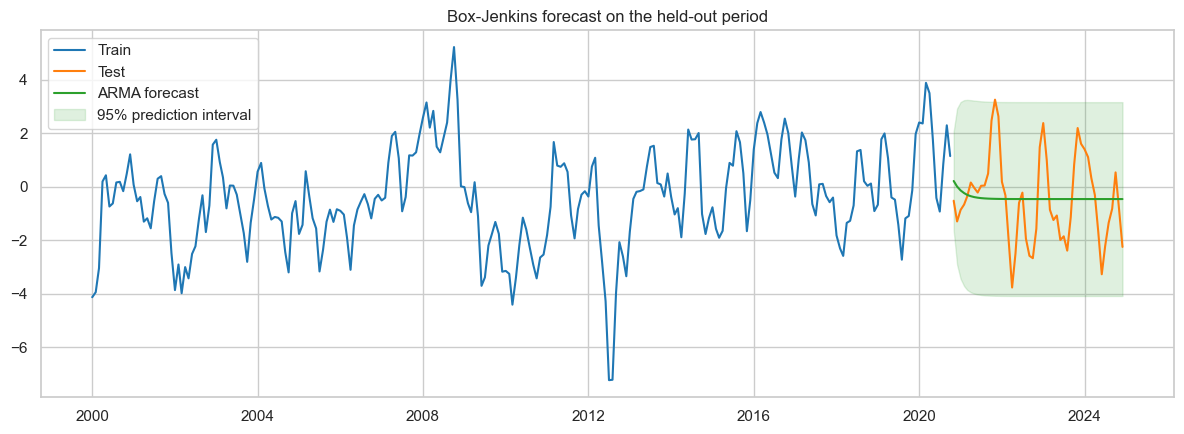

      ARMA  Naive
MAE    1.3  1.942
RMSE   1.6  2.264


In [12]:
forecast = best_fit.get_forecast(steps=len(test))
mean_forecast = pd.Series(forecast.predicted_mean.values, index=test.index, name="forecast")
conf_int = forecast.conf_int()
lower = pd.Series(conf_int.iloc[:, 0].values, index=test.index)
upper = pd.Series(conf_int.iloc[:, 1].values, index=test.index)

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(train.index, train, label="Train", color="tab:blue")
ax.plot(test.index, test, label="Test", color="tab:orange")
ax.plot(test.index, mean_forecast, label="ARMA forecast", color="tab:green")
ax.fill_between(
    test.index,
    lower.values,
    upper.values,
    color="tab:green",
    alpha=0.15,
    label="95% prediction interval",
)
ax.set_title("Box-Jenkins forecast on the held-out period")
ax.legend()
plt.tight_layout()
plt.show()

naive_forecast = np.repeat(train.iloc[-1], len(test))
metrics = pd.DataFrame(
    {
        "ARMA": [
            mean_absolute_error(test, mean_forecast),
            np.sqrt(mean_squared_error(test, mean_forecast)),
        ],
        "Naive": [
            mean_absolute_error(test, naive_forecast),
            np.sqrt(mean_squared_error(test, naive_forecast)),
        ],
    },
    index=["MAE", "RMSE"],
)
print(metrics.round(3).to_string())

### Step 6: Iterate

If diagnostics fail, or if the forecast is biased, go back to identification. The Box-Jenkins loop
is intentionally iterative: identification, estimation, diagnostic checking, and forecasting are
not a one-way pipeline.

## 7. Intervention analysis and structural breaks

Classical ARIMA assumes that the data-generating process is stable. Real series often contain:

- **pulses:** one-period shocks, such as a system outage;
- **level shifts:** permanent changes, such as a policy change;
- **temporary changes:** shocks that decay gradually;
- **seasonal breaks:** a change in the seasonal pattern.

One simple intervention model adds a dummy variable to the mean equation:

`y_t = beta x_t + eta_t`,

where `x_t` is 0 before the intervention and 1 afterwards, and `eta_t` follows an ARIMA process.
This can be estimated with `SARIMAX(endog, exog=...)` in statsmodels. More complex interventions use
pulse dummies, ramp effects, or transfer functions.

A structural break is different from an outlier: it changes the parameters of the process, so
fitting one ARIMA model to the whole sample can produce misleading forecasts. Plot the series,
inspect rolling estimates, and consider splitting the sample or modelling the break explicitly.

## 8. Cautions

1. **Stationarity is a modelling decision, not a formality.** Check plots, ACF/PACF, ADF, and KPSS
   before choosing `d`.
2. **Do not over-difference.** Differencing a stationary series can create an unnecessary MA unit
   root and inflate forecast variance.
3. **Beware spurious regression.** Two unrelated trending series can appear correlated. Difference
   or detrend, and prefer models that respect the data-generating process.
4. **Seasonality needs a seasonal model.** Use seasonal differencing and SARIMA terms rather than
   ignoring a repeating pattern.
5. **Structural breaks and outliers can invalidate the model.** A single ARIMA fit may not be
   stable across a pandemic, a policy change, or a platform migration.
6. **Information criteria are relative.** AIC and BIC compare candidate models on the same data;
   they do not prove that the chosen model is true.
7. **Residual diagnostics are necessary but not sufficient.** White-noise residuals do not
   guarantee good forecasts or causal validity.
8. **Report forecast uncertainty.** Point forecasts without intervals overstate confidence.
9. **ARIMA is not a causal model.** It describes autocorrelation and conditional mean dynamics. A
   coefficient on lagged `y` is not, by itself, a causal effect.
10. **Small samples make identification unstable.** Sample ACF/PACF estimates are noisy, and
    seasonal or high-order models may not be estimable.

## 9. Exercises

1. Simulate an MA(2) process and identify the cutoff in the ACF. Fit MA(1), MA(2), and MA(3)
   models and compare AIC/BIC.
2. Simulate a random walk with drift. Decide whether to use a constant, a trend, or differencing.
3. Fit the candidate models on a rolling origin and compare one-step-ahead forecast errors.
4. Add a pulse intervention to a simulated series and estimate it with `SARIMAX(exog=...)`.
5. Create a seasonal series and compare ARIMA with SARIMA using a seasonal difference.
6. Deliberately over-difference a stationary series and observe the MA unit root in the ACF and
   roots.
7. Write a short Box-Jenkins report for a real series: identification, estimation, diagnostics,
   forecast, and limitations.

## Key takeaways

- AR models depend on past values; MA models depend on past shocks; ARMA combines both.
- ARIMA applies ARMA after differencing.
- Box-Jenkins is an iterative loop: identify, estimate, check residuals, forecast, and revise.
- ACF/PACF patterns guide identification, but information criteria and out-of-sample tests decide.
- Residual diagnostics and prediction intervals are essential parts of the result.
- Stationarity, over-differencing, seasonality, structural breaks, and causal interpretation are the
  main practical cautions.